# LAB 10 — Time Series Fundamentals & Forecasting Baselines

**Module:** Time Series Fundamentals & Forecasting Baselines
**Session:** 10
**Duration:** 150 minutes, plus optional Advanced Challenges
**Audience:** LAB02-LAB09'u tamamlamış katılımcılar (başlangıç seviyesi ağırlıklı, az sayıda deneyimli katılımcı)

## LAB02-LAB09'dan Geçiş

LAB02-LAB09 boyunca klasik **tabular Machine Learning** ile çalıştık: her satır bağımsız bir
gözlem, random train/test split yeterliydi (LAB08/LAB09'daki group-aware chronological split
istisnasıyla). LAB10'dan itibaren **Time Series Forecasting** alanına geçiyoruz: gözlemler
zamansal sıralamaya sahip, geçmiş gözlemler gelecek hakkında bilgi taşıyabilir, ve bu nedenle
evaluation protokolü köklü biçimde değişir.

Bu LAB'ın amacı karmaşık bir forecasting modeli eğitmek değildir. Amaç:

1. Time Series verisinin temel özelliklerini ve klasik tabular veriden farkını anlamak.
2. Leakage-safe bir chronological evaluation protocol kurmak.
3. Üç basit ama güçlü **baseline forecasting yöntemi** (Naive, Seasonal Naive, Moving Average)
   geliştirmek.
4. Bu baseline'ları **Rolling-Origin Evaluation** ile doğru biçimde karşılaştırmak.
5. LAB11 (Machine Learning for Time Series Forecasting) ve LAB12 (End-to-End ML PoC) için
   yeniden kullanılabilir bir split/evaluation protokolü ve referans sonuç seti hazırlamak.

## Learning Objectives

Bu LAB sonunda katılımcılar:

1. Time Series ve klasik tabular veri arasındaki farkı açıklayabilecek.
2. Forecasting ve Regression arasındaki ilişkiyi anlayacak.
3. Frequency, Granularity ve Temporal Dependency kavramlarını açıklayabilecek.
4. Trend, Seasonality, Noise ve Autocorrelation kavramlarını yorumlayabilecek.
5. Zaman indeksine sahip bir Pandas Series oluşturabilecek.
6. Missing Dates ve Duplicate Timestamps kontrolleri gerçekleştirebilecek.
7. Forecast Origin ve Forecast Horizon tanımlayabilecek.
8. Chronological Train/Validation/Test Split uygulayabilecek.
9. Temporal Leakage risklerini belirleyebilecek.
10. Naive, Seasonal Naive ve Moving Average forecasting geliştirebilecek.
11. MAE, RMSE, WAPE ve MASE hesaplayabilecek.
12. Rolling-Origin Evaluation uygulayabilecek.
13. Baseline modellerini karşılaştırabilecek ve iş açısından yorumlayabilecek.
14. LAB11 için güvenilir bir evaluation protocol'ü devralabilecek.

## Dataset

**Bike Sharing in Washington D.C.** (`data/bike_sharing/day.csv`) — Kaggle:
[marklvl/bike-sharing-dataset](https://www.kaggle.com/datasets/marklvl/bike-sharing-dataset),
orijinal kaynak UCI Machine Learning Repository:
[Bike Sharing Dataset](https://archive.ics.uci.edu/dataset/275/bike-sharing-dataset)
(DOI: [10.24432/C5W894](https://doi.org/10.24432/C5W894)), Hadi Fanaee-T ve João Gama, CC BY 4.0
lisansı. Bu LAB'da **yalnızca `day.csv`** kullanılır (`hour.csv` yalnızca isteğe bağlı Advanced
Challenge 4'te kullanılır).

## Business Problem

**Daily Bike Rental Demand Forecasting** — geçmiş günlük kiralama sayılarını kullanarak gelecek
**14 gün** için günlük toplam kiralama sayısını (`cnt`) tahmin etmek. Bu, operasyonel olarak
Fleet Capacity Planning, Resource Allocation, Maintenance Planning, Staffing Decisions ve Service
Capacity Planning kararlarını besler.

**Önemli iş sınırlaması:** `cnt`, *gözlenen* kiralama sayısıdır. Dataset'te karşılanamayan talep
(unmet demand) veya mevcut bisiklet kapasitesi bilgisi bulunmadığından, `cnt`'nin gerçek
unconstrained demand'i kusursuz temsil ettiği iddia edilemez.


---

## Section 1 — Time Series & Forecasting Fundamentals
**Süre: 15 dakika**

### Learning Objective

Zaman serisi verilerinin temel özelliklerini ve forecasting problemlerinin klasik Machine
Learning problemlerinden farkını anlamak.

### Concept Explanation

- **Time Series:** Gözlemlerin zamansal sıraya sahip olduğu veri. Sıra, bilginin kendisinin bir
  parçasıdır — satırları rastgele karıştırmak bilgi kaybına yol açar.
- **Time Series vs Tabular Data:** Klasik tabular veride satırlar genellikle **bağımsız** kabul
  edilir (i.i.d. varsayımı). Time Series'te bir gözlem, kendisinden önceki gözlemlerle
  **temporal dependency** taşıyabilir — ama bu bağımlılığın varlığı/gücü *veri üzerinden*
  değerlendirilmelidir, asla varsayılmamalıdır.
- **Forecasting vs Regression:** Forecasting, regression'ın özel bir türüdür — feature'lar
  genellikle geçmiş gözlemlerden (lag, rolling statistics) türetilir ve değerlendirme her zaman
  **kronolojik olarak ileriye doğru** yapılır.
- **Frequency:** Gözlemler arasındaki zaman aralığı (örn. günlük = `D`).
- **Granularity:** Gözlemlerin detay seviyesi (günlük toplam vs saatlik toplam).
- **Forecast Origin (`T`):** Tahminin üretildiği, o ana kadarki tüm geçmişin mevcut olduğu zaman
  noktası.
- **Forecast Horizon (`h`):** Forecast origin'den itibaren tahmin edilecek gelecek adım sayısı.
- **One-Step vs Multi-Step Forecasting:** Tek bir gelecek adımı mı (`h=1`), yoksa birden fazla
  ardışık adım mı (`h=1..H`) tahmin ediliyor.
- **Univariate vs Multivariate Forecasting:** Tek bir seri mi (`cnt`), yoksa birden fazla seri
  birlikte mi modelleniyor.
- **Exogenous Variables:** Hedef seriden bağımsız olarak var olan, ancak tahmini etkileyebilecek
  dış değişkenler (örn. hava durumu) — LAB10'da **kullanılmayacak** (Section 4'te nedeni
  açıklanacak), LAB11'de ayrıca ele alınabilir.

### Mathematical Representation

Tarihsel zaman serisi:

$$y_1, y_2, \ldots, y_T$$

Forecast:

$$\hat{y}_{T+h}$$

Burada `T` forecast origin, `h` forecast horizon adımı, `ŷ` tahmin edilen değerdir.

### Hands-On Demonstration

Küçük, tamamen **sentetik** (gerçek dataset değil) bir zaman serisi üzerinde forecast origin ve
horizon kavramlarını görselleştirelim.

### Educational Question

**"Time Series Forecasting probleminde neden klasik random train/test split kullanmak çoğu
zaman uygun değildir?"**

Yanıt: Random split, forecast origin'den **sonraki** gözlemleri training set'e sızdırabilir
(temporal leakage). Gerçek production senaryosunda, forecast origin anında gelecekteki hiçbir
gözlem mevcut değildir (information availability). Bu nedenle evaluation, modelin gerçekten
*geçmişten geleceği* tahmin etme yeteneğini ölçmelidir — rastgele karıştırılmış bir split bunu
asla ölçemez.


In [1]:
# Same environment setup pattern as LAB02-LAB09.
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from data_loading import load_config, load_bike_sharing_daily  # noqa: E402

config = load_config()
lab10_cfg = config["lab10"]
print("Project root:", PROJECT_ROOT)
print("lab10 config loaded:", list(lab10_cfg.keys()))

Project root: C:\Users\pc\ml-labs
lab10 config loaded: ['target', 'forecasting', 'split', 'backtesting', 'evaluation', 'artifacts']


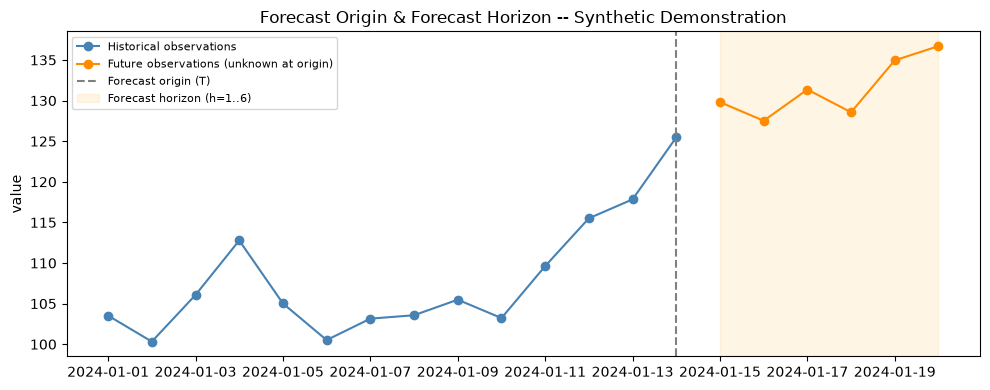

Forecast origin (T): 2024-01-14
Forecast horizon dates: [datetime.date(2024, 1, 15), datetime.date(2024, 1, 16), datetime.date(2024, 1, 17), datetime.date(2024, 1, 18), datetime.date(2024, 1, 19), datetime.date(2024, 1, 20)]


In [2]:
# Synthetic demonstration series -- NOT the real dataset, purely illustrative.
rng = np.random.default_rng(42)
demo_index = pd.date_range("2024-01-01", periods=20, freq="D")
demo_values = 100 + np.cumsum(rng.normal(2, 5, size=20))
demo_series = pd.Series(demo_values, index=demo_index, name="demo_value")

forecast_origin = demo_series.index[13]  # 14 historical observations
forecast_horizon_demo = 6
future_dates = pd.date_range(forecast_origin + pd.Timedelta(days=1), periods=forecast_horizon_demo, freq="D")

fig, ax = plt.subplots(figsize=(10, 4))
history_part = demo_series.loc[:forecast_origin]
future_part = demo_series.loc[future_dates[0]:future_dates[-1]]
ax.plot(history_part.index, history_part.values, "o-", color="steelblue", label="Historical observations")
ax.plot(future_part.index, future_part.values, "o-", color="darkorange", label="Future observations (unknown at origin)")
ax.axvline(forecast_origin, color="gray", linestyle="--", label="Forecast origin (T)")
ax.axvspan(future_dates[0], future_dates[-1], color="orange", alpha=0.1, label="Forecast horizon (h=1..6)")
ax.set_title("Forecast Origin & Forecast Horizon -- Synthetic Demonstration")
ax.legend(loc="upper left", fontsize=8)
ax.set_ylabel("value")
plt.tight_layout()
plt.show()

print("Forecast origin (T):", forecast_origin.date())
print("Forecast horizon dates:", [d.date() for d in future_dates])

---

## Section 2 — Dataset Audit & Time Index Preparation
**Süre: 20 dakika**

### Learning Objective

Tarih indeksine sahip, güvenilir bir günlük (daily) time series hazırlamak.

### Part A — Dataset Loading

Dataset path, mevcut YAML configuration (`config/settings.yaml`) ve `pathlib` üzerinden
yönetilir (hardcoded Windows path kullanılmaz; bu LAB07-LAB09'daki `load_*` fonksiyon deseniyle
birebir aynıdır, bkz. `src/data_loading.py`).


In [3]:
df = load_bike_sharing_daily(config)
print("shape:", df.shape)
print("columns:", list(df.columns))

shape: (731, 16)
columns: ['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']


### Part B — Dataset Inspection

Aşağıdaki kontroller gerçek CSV üzerinden ölçülür (varsayılmaz).

In [4]:
print("dtypes:")
print(df.dtypes)
print()
print("missing values (total):", df.isna().sum().sum())
print("duplicate dteday values:", df["dteday"].duplicated().sum())
print("negative cnt count:", (df["cnt"] < 0).sum())
print("zero cnt count:", (df["cnt"] == 0).sum())

dtypes:
instant         int64
dteday            str
season          int64
yr              int64
mnth            int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object

missing values (total): 0
duplicate dteday values: 0
negative cnt count: 0
zero cnt count: 0


### Part C — Date Parsing

`dteday` alanı datetime formatına dönüştürülür. `errors="raise"`, sessizce geçersiz tarihleri
`NaT`'a çevirmek yerine açık bir hata fırlatır.

In [5]:
df["dteday"] = pd.to_datetime(df["dteday"], errors="raise")
print("dteday dtype after parsing:", df["dteday"].dtype)
print("date range:", df["dteday"].min().date(), "->", df["dteday"].max().date())

df = df.sort_values("dteday").reset_index(drop=True)
print("sorted chronologically, first/last rows match date range:",
      df["dteday"].iloc[0] == df["dteday"].min(), df["dteday"].iloc[-1] == df["dteday"].max())

dteday dtype after parsing: datetime64[us]
date range: 2011-01-01 -> 2012-12-31
sorted chronologically, first/last rows match date range: True True


### Part D — Create Daily Time Series

`dteday` index, `cnt` target Series olarak seçilir.

In [6]:
TARGET_COLUMN = lab10_cfg["target"]["column"]

daily_series = (
    df
    .set_index("dteday")[TARGET_COLUMN]
    .sort_index()
)
print("daily_series length:", len(daily_series))
daily_series.head()

daily_series length: 731


dteday
2011-01-01     985
2011-01-02     801
2011-01-03    1349
2011-01-04    1562
2011-01-05    1600
Name: cnt, dtype: int64

### Part E — Time Index Validation

In [7]:
def validate_daily_series(series: pd.Series) -> dict:
    # Validate a daily-frequency time series: monotonicity, uniqueness, and calendar
    # coverage. Returns a dict so results can be inspected and asserted on.
    full_range = pd.date_range(series.index.min(), series.index.max(), freq="D")
    missing_dates = sorted(set(full_range) - set(series.index))
    return {
        "is_monotonic_increasing": bool(series.index.is_monotonic_increasing),
        "is_unique": bool(series.index.is_unique),
        "n_observations": len(series),
        "start_date": series.index.min(),
        "end_date": series.index.max(),
        "expected_days_in_range": len(full_range),
        "missing_calendar_dates": missing_dates,
    }


series_report = validate_daily_series(daily_series)
for key, value in series_report.items():
    if key != "missing_calendar_dates":
        print(f"{key}: {value}")
print("missing_calendar_dates count:", len(series_report["missing_calendar_dates"]))

assert series_report["is_monotonic_increasing"], "Time index must be monotonic increasing."
assert series_report["is_unique"], "Time index must not contain duplicate dates."
print("\nTime index integrity: OK")

is_monotonic_increasing: True
is_unique: True
n_observations: 731
start_date: 2011-01-01 00:00:00
end_date: 2012-12-31 00:00:00
expected_days_in_range: 731
missing_calendar_dates count: 0

Time index integrity: OK


**Missing Date Strategy:** Bu veri kümesinde (yukarıdaki kontrol sonucuna göre) eksik takvim
günü bulunmamaktadır. Genel kural olarak: bir tarihin veri kümesinde bulunmaması **otomatik
olarak sıfır kiralama anlamına gelmez** (örneğin veri toplama kesintisi olabilir) — eksik
tarihler varsa raporlanmalı, gerekçesiz biçimde sıfırla doldurulmamalıdır.

### Part F — Protected Period Awareness

Bu bölümde tüm CSV, şema/kalite kontrolleri için okunabilir (yukarıda yaptığımız gibi). Ancak
Section 4'te tanımlanacak **Protected Test Period**'un hedef (`cnt`) değerleri, bu noktadan
itibaren development analizine (trend, seasonality, autocorrelation, baseline seçimi) **dahil
edilmeyecektir**. Section 3'ten başlayarak tüm exploratory görselleştirmeler sadece Training
Period ile sınırlandırılacaktır.

---

## Section 3 — Trend, Seasonality & Autocorrelation
**Süre: 25 dakika**

### Learning Objective

Zaman serisinin farklı bileşenlerini (trend, seasonality, noise, autocorrelation) görsel ve
istatistiksel olarak değerlendirmek.

### Important Rule

Bu bölümdeki **tüm** target-based exploratory analiz, Section 4'te tanımlanacak split
konfigürasyonunu burada önceden kullanarak, **yalnızca Training Period** üzerinde yapılır.
Validation ve Test dönemindeki `cnt` değerleri bu analizlere dahil edilmez.

In [8]:
split_cfg = lab10_cfg["split"]
train_series = daily_series.loc[split_cfg["training_start"]:split_cfg["training_end"]]
print("Training period:", train_series.index.min().date(), "->", train_series.index.max().date())
print("Training period n_observations:", len(train_series))

Training period:

 2011-01-01 -> 2012-08-31
Training period n_observations: 609


### Part A — Historical Daily Rentals (Training Period)

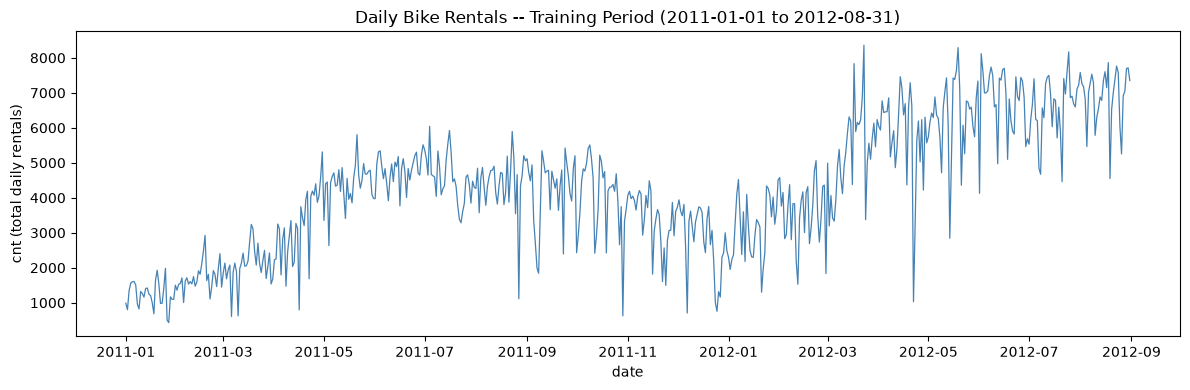

In [9]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(train_series.index, train_series.values, color="steelblue", linewidth=0.9)
ax.set_title("Daily Bike Rentals -- Training Period (2011-01-01 to 2012-08-31)")
ax.set_xlabel("date")
ax.set_ylabel("cnt (total daily rentals)")
plt.tight_layout()
plt.show()

### Part B — Trend Analysis (Rolling Mean)

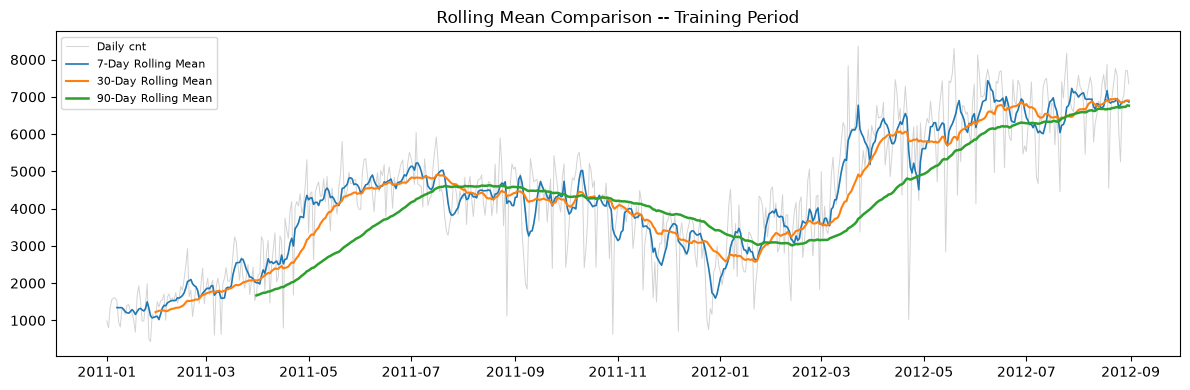

First 90 days mean: 1671.7
Last 90 days mean: 6763.3
Last 90-day rolling mean value: 6763.3


In [10]:
rolling_mean_7 = train_series.rolling(window=7, min_periods=7).mean()
rolling_mean_30 = train_series.rolling(window=30, min_periods=30).mean()
rolling_mean_90 = train_series.rolling(window=90, min_periods=90).mean()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(train_series.index, train_series.values, color="lightgray", linewidth=0.7, label="Daily cnt")
ax.plot(rolling_mean_7.index, rolling_mean_7.values, label="7-Day Rolling Mean", linewidth=1.2)
ax.plot(rolling_mean_30.index, rolling_mean_30.values, label="30-Day Rolling Mean", linewidth=1.5)
ax.plot(rolling_mean_90.index, rolling_mean_90.values, label="90-Day Rolling Mean", linewidth=1.8)
ax.set_title("Rolling Mean Comparison -- Training Period")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print("First 90 days mean:", round(train_series.iloc[:90].mean(), 1))
print("Last 90 days mean:", round(train_series.iloc[-90:].mean(), 1))
print("Last 90-day rolling mean value:", round(rolling_mean_90.iloc[-1], 1))

**Yorum:** Training period'ın ilk 90 günü ile son 90 günü arasındaki ortalama farkı net bir
**yükselen trend** gösteriyor (ilk 90 gün ortalaması ≈1672 vs son 90 gün ortalaması ≈6763).
90-Day Rolling Mean, kısa dönemli (haftalık) dalgalanmaları büyük ölçüde düzleştirirken, bu
uzun dönemli trend'i açıkça ortaya koyuyor. 7-Day Rolling Mean ise haftalık dalgalanmaları
büyük oranda korur -- window büyüdükçe kısa dönemli gürültü azalır ama trend'e tepki hızı da
düşer. **Not:** Gerçek veride gözlenmemiş bir trend'i varmış gibi sunmuyoruz -- bu artış gerçek
ölçümdür.

### Part C — Weekly Seasonality

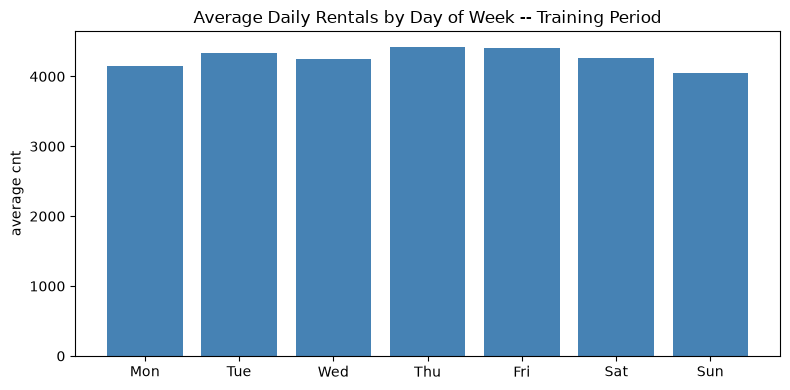

{'Mon': np.float64(4145.7), 'Tue': np.float64(4341.3), 'Wed': np.float64(4242.1), 'Thu': np.float64(4423.7), 'Fri': np.float64(4413.1), 'Sat': np.float64(4258.9), 'Sun': np.float64(4047.5)}

Weekday average: 4313.2
Weekend average: 4153.2


In [11]:
weekday_average = train_series.groupby(train_series.index.day_of_week).mean()
weekday_labels = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(weekday_labels, weekday_average.values, color="steelblue")
ax.set_title("Average Daily Rentals by Day of Week -- Training Period")
ax.set_ylabel("average cnt")
plt.tight_layout()
plt.show()

print(dict(zip(weekday_labels, weekday_average.round(1).values)))

is_weekend = train_series.index.day_of_week >= 5
print("\nWeekday average:", round(train_series[~is_weekend].mean(), 1))
print("Weekend average:", round(train_series[is_weekend].mean(), 1))

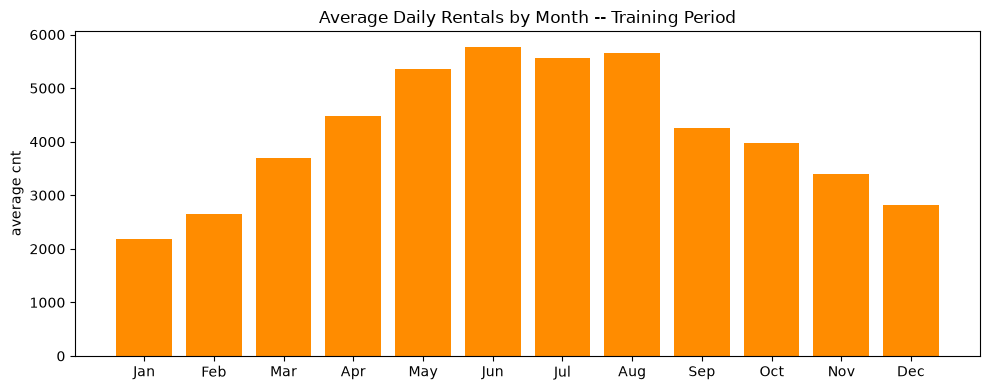

{1: 2176.3, 2: 2655.3, 3: 3692.3, 4: 4484.9, 5: 5349.8, 6: 5772.4, 7: 5563.7, 8: 5664.4, 9: 4247.3, 10: 3984.2, 11: 3405.6, 12: 2816.9}


In [12]:
monthly_average = train_series.groupby(train_series.index.month).mean()
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar([month_labels[m - 1] for m in monthly_average.index], monthly_average.values, color="darkorange")
ax.set_title("Average Daily Rentals by Month -- Training Period")
ax.set_ylabel("average cnt")
plt.tight_layout()
plt.show()

print(monthly_average.round(1).to_dict())

**Yorum:** Weekday/weekend ortalamaları birbirine yakın (günlük toplam `cnt` =
`casual + registered`; hafta içi registered-commuter kullanımı, hafta sonu casual kullanımla
telafi oluyor olabilir). Monthly pattern ise güçlü bir **yıl-içi (within-year) seasonality**
gösteriyor: kış aylarında (Ocak-Şubat) düşük, yaz aylarında (Haziran-Ağustos) yüksek ortalama
kiralama -- hava koşullarıyla tutarlı.

### Part D — Annual Seasonality

Dataset yaklaşık **2 yıllık** günlük gözlem içeriyor. Bu, within-year (aylık) bir pattern'i
göstermeye yeterli olsa da, **yıldan yıla tekrar eden** (year-over-year) bir annual seasonality
pattern'inin güçlü ve kararlı olduğunu istatistiksel olarak doğrulamak için yalnızca 2 gözlem
noktası (2011 ve 2012) yeterli değildir. Bu nedenle LAB10'un ana forecasting **seasonal period**
değeri, daha güvenilir biçimde gözlenebilen **haftalık** pattern'e dayanarak **7** olarak
belirlenmiştir (aşağıdaki autocorrelation sonuçlarıyla da desteklenmektedir).

### Part E — Autocorrelation

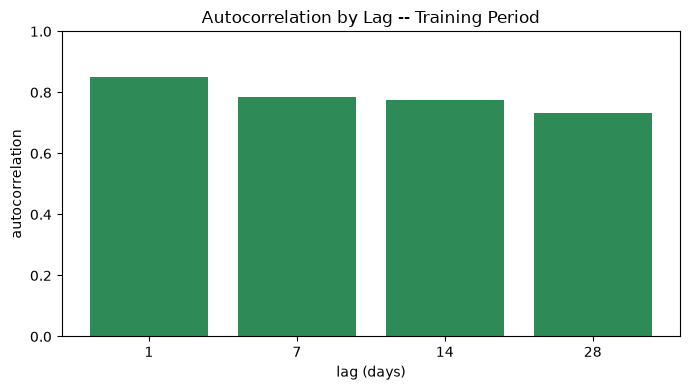

lag 1: 0.8514
lag 7: 0.7858
lag 14: 0.7747
lag 28: 0.7340


In [13]:
autocorr_lags = [1, 7, 14, 28]
autocorr_values = {lag: train_series.autocorr(lag=lag) for lag in autocorr_lags}

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar([str(lag) for lag in autocorr_lags], list(autocorr_values.values()), color="seagreen")
ax.set_title("Autocorrelation by Lag -- Training Period")
ax.set_xlabel("lag (days)")
ax.set_ylabel("autocorrelation")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

for lag, value in autocorr_values.items():
    print(f"lag {lag}: {value:.4f}")

**Yorum:**

- **Lag 1** (≈0.85) çok yüksek: ardışık günler arasında güçlü bir ilişki var -- bu, hem trend
  hem de genel gün-be-gün süreklilik etkisinin bir kombinasyonu olabilir.
- **Lag 7** (≈0.79) da yüksek: haftalık seasonality'nin varlığına işaret ediyor (7 gün önceki
  aynı haftanın-günü ile güçlü ilişki).
- **Lag 14** (≈0.77) ve **Lag 28** (≈0.73) da görece yüksek kalıyor -- ancak bu sadece haftalık
  seasonality'den değil, aynı zamanda genel trend'den de kaynaklanabilir (trend varken uzak
  lag'lerde de yapay olarak yüksek autocorrelation gözlenebilir).
- **Önemli uyarı:** Autocorrelation bir **nedensellik (causality)** göstergesi değildir, sadece
  istatistiksel bir ilişki ölçümüdür; trend ve seasonality birbirini etkileyebilir, bu yüzden
  tek bir lag değerini izole yorumlamak yanıltıcı olabilir.

### Technical Limitations

Rolling mean, seasonality ve autocorrelation analizleri **tanımlayıcıdır (descriptive)**. Bu
grafiklerden tek başına bir production-ready forecasting performance sonucu çıkarılamaz --
gerçek performans Section 6-7'de validation seti üzerinde ölçülecektir.

---

## Section 4 — Forecasting Problem & Temporal Splitting
**Süre: 20 dakika**

Bu bölüm LAB10, LAB11 ve LAB12 için **ortak evaluation protocol'ünü** oluşturur.

### Learning Objective

Forecasting probleminde leakage-safe chronological splitting gerçekleştirmek.

### Business Problem

**Next 14 Days Daily Bike Rental Forecasting** — Target: `cnt`, Frequency: Daily.

In [14]:
forecasting_cfg = lab10_cfg["forecasting"]
FORECAST_HORIZON = forecasting_cfg["horizon"]
SEASONAL_PERIOD = forecasting_cfg["seasonal_period"]
MOVING_AVERAGE_WINDOW = forecasting_cfg["moving_average_window"]
print("forecast_horizon:", FORECAST_HORIZON)
print("seasonal_period:", SEASONAL_PERIOD)
print("moving_average_window:", MOVING_AVERAGE_WINDOW)

forecast_horizon: 14
seasonal_period: 7
moving_average_window: 7


### Chronological Split

Split sınırları `config/settings.yaml`'ın `lab10.split` bloğunda yönetilir (hardcode edilmez).
Gerçek dataset ile uyumluluğu aşağıda doğrulanır.

In [15]:
def create_temporal_split(series: pd.Series, split_cfg: dict) -> dict:
    # Slice a daily series into training/validation/protected-test periods using
    # config-driven chronological boundaries. Returns the three sub-series plus their
    # observation counts, computed from the real data (never hardcoded).
    train = series.loc[split_cfg["training_start"]:split_cfg["training_end"]]
    validation = series.loc[split_cfg["validation_start"]:split_cfg["validation_end"]]
    test = series.loc[split_cfg["test_start"]:split_cfg["test_end"]]
    return {
        "train": train, "validation": validation, "test": test,
        "train_count": len(train), "validation_count": len(validation), "test_count": len(test),
    }


split_result = create_temporal_split(daily_series, split_cfg)
train_series = split_result["train"]
validation_series = split_result["validation"]
test_series = split_result["test"]

print("Training:  ", split_result["train_count"], "days", train_series.index.min().date(), "->", train_series.index.max().date())
print("Validation:", split_result["validation_count"], "days", validation_series.index.min().date(), "->", validation_series.index.max().date())
print("Test:      ", split_result["test_count"], "days (PROTECTED -- target values not used below)",
      test_series.index.min().date(), "->", test_series.index.max().date())
print("\nTotal accounted:", split_result["train_count"] + split_result["validation_count"] + split_result["test_count"], "of", len(daily_series))

Training:   609 days 2011-01-01 -> 2012-08-31
Validation: 61 days 2012-09-01 -> 2012-10-31
Test:       61 days (PROTECTED -- target values not used below) 2012-11-01 -> 2012-12-31

Total accounted: 731 of 731


### Split Integrity

In [16]:
train_end = train_series.index.max()
val_start = validation_series.index.min()
val_end = validation_series.index.max()
test_start = test_series.index.min()

assert train_end < val_start, "Training period must end before Validation period starts."
assert val_end < test_start, "Validation period must end before Test period starts."

combined_index = train_series.index.append(validation_series.index).append(test_series.index)
assert combined_index.is_unique, "No overlapping timestamps allowed across periods."

print("train_end < validation_start:", train_end < val_start)
print("validation_end < test_start:", val_end < test_start)
print("no overlapping timestamps:", combined_index.is_unique)
print("combined period covers full dataset:", len(combined_index) == len(daily_series))

train_end < validation_start: True
validation_end < test_start: True
no overlapping timestamps: True
combined period covers full dataset: True


### Data Leakage Discussion

**Incorrect:** Historical gözlemleri rastgele karıştırıp (shuffle), gelecekteki forecasting
performansını bu rastgele split üzerinden değerlendirmek. Bu durumda, forecast origin'den
*sonraki* gerçek değerler yanlışlıkla "geçmiş" olarak training set'e girebilir -- model, gerçek
production'da asla sahip olamayacağı bilgiye (gelecekteki değerlere) training sırasında maruz
kalır.

**Correct:** Modeli geçmiş (kronolojik olarak önceki) gözlemler üzerinde "eğitmek" (baseline
forecasting'de bu sadece son gözlemlere bakmak demektir) ve performansı **daha sonraki**
kronolojik dönem üzerinde değerlendirmek.

**Forecast input leakage örneği:** Eğer bir forecasting fonksiyonu, forecast origin'den *sonraki*
günlere ait gerçekleşmiş `cnt` değerlerini (veya bu değerlerden türetilmiş herhangi bir istatistiği)
girdilerinin bir parçası olarak kullanırsa, bu **temporal leakage**'dır -- üretilen "tahmin"
gerçekte zaten gerçekleşmiş bir değeri kopyalamaktan ibarettir ve production'da üretilemez.

### Forecast Origin & Forecast Horizon (Section 1 Recap)

- **Forecast Origin (`T`):** Bir forecast'ın üretildiği, o anda mevcut bütün tarihsel bilginin
  sonlandığı zaman noktası.
- **Forecast Horizon (`h`):** Forecast origin'den itibaren tahmin edilecek gelecek zaman adımı
  sayısı (bu LAB'da `h = 1..14`).

### Protected Test Set

Test period (`2012-11-01` - `2012-12-31`, 61 gün) bu LAB boyunca **sadece split-integrity
doğrulaması için satır sayısı olarak** kullanılmıştır. Bu LAB içerisinde:

- Test period için **hiçbir forecast üretilmemiştir.**
- Test period için **hiçbir metrik hesaplanmamıştır.**
- Test period `cnt` değerleri **hiçbir grafikte görselleştirilmemiştir.**
- Test period **hiçbir baseline seçimini etkilememiştir.**

Test hedefinin Python değişkeninde (`test_series`) teknik olarak erişilebilir olması, bu
değerlerin analiz için kullanılmasını meşrulaştırmaz. Bu korumayı LAB11 boyunca da sürdüreceğiz;
test seti nihai olarak LAB12'de kullanılacaktır.

### Student Exercise

Training, Validation ve Test dönemlerini zaman ekseninde gösteren bir plot (test period için
hedef değerleri **çizmeden**, sadece tarih aralığını arka plan bölgesi olarak göstererek).

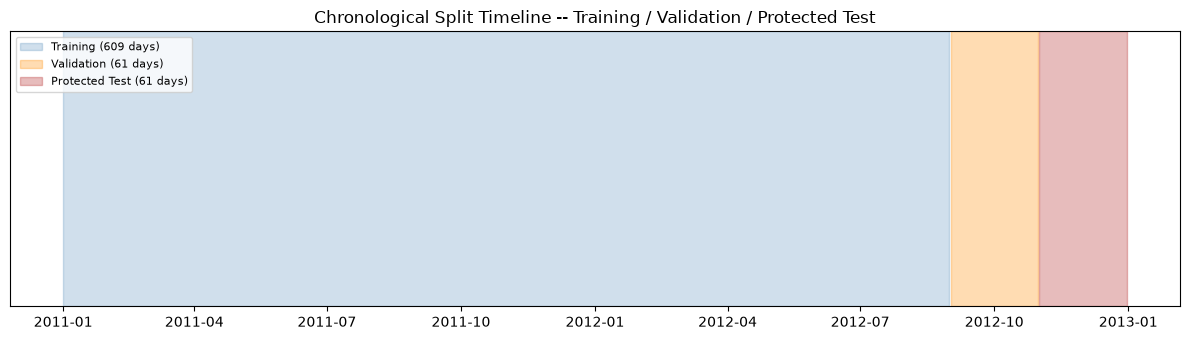

Note: Test period region shown as date range only -- no cnt values are plotted or read for Test.


In [17]:
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.axvspan(train_series.index.min(), train_series.index.max(), color="steelblue", alpha=0.25, label=f"Training ({split_result['train_count']} days)")
ax.axvspan(validation_series.index.min(), validation_series.index.max(), color="darkorange", alpha=0.3, label=f"Validation ({split_result['validation_count']} days)")
ax.axvspan(test_series.index.min(), test_series.index.max(), color="firebrick", alpha=0.3, label=f"Protected Test ({split_result['test_count']} days)")
ax.set_title("Chronological Split Timeline -- Training / Validation / Protected Test")
ax.set_yticks([])
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

print("Note: Test period region shown as date range only -- no cnt values are plotted or read for Test.")

---


Section 5'te asıl forecasting baseline'larını geliştireceğiz: Naive, Seasonal Naive ve Moving
Average.

---

## Section 5 — Naive & Seasonal Naive Forecasting
**Süre: 25 dakika**

Bu LAB'ın ana forecasting uygulama bölümüdür.

### Learning Objective

Herhangi bir kompleks estimator kullanmadan, güçlü ve doğru baseline forecasting yöntemleri
geliştirmek.

### Part A — Naive Forecasting

**Naive Forecast:** Gelecekteki bütün horizon tahminleri, forecast origin anında gözlenen son
değere eşittir.

$$\hat{y}_{T+h} = y_T \quad \text{for } h = 1, \ldots, H$$

In [18]:
def naive_forecast(history: pd.Series, horizon: int) -> np.ndarray:
    # Repeat the last observed value for the full forecast horizon. Uses only
    # observations already in `history` -- never touches future values.
    if len(history) < 1:
        raise ValueError("naive_forecast requires at least 1 historical observation.")
    last_value = history.iloc[-1]
    return np.full(horizon, last_value, dtype=float)


# Quick sanity check on a small slice
_demo_history = train_series.iloc[:30]
_demo_preds = naive_forecast(_demo_history, horizon=5)
print("naive_forecast output length:", len(_demo_preds))
print("naive_forecast output (constant, = last historical value):", _demo_preds)

naive_forecast output length: 5
naive_forecast output (constant, = last historical value): [1096. 1096. 1096. 1096. 1096.]


### Part B — Seasonal Naive Forecasting

Haftalık seasonality için (`seasonal_period = 7`): forecast origin anında gözlenen son 7 günün
değerleri, gelecek horizon boyunca tekrarlanır.

$$\hat{y}_{T+h} = y_{T+h - m \lceil h/m \rceil} \quad \text{where } m = \text{seasonal period}$$

Bu ifade, yalnızca `T` anında ve öncesinde zaten gözlenmiş değerlerin kullanılmasını sağlar --
hiçbir gelecek gözlem gerekmez.

In [19]:
def seasonal_naive_forecast(history: pd.Series, horizon: int, seasonal_period: int) -> np.ndarray:
    # Repeat the last `seasonal_period` historical values, tiled to cover the full
    # horizon. Requires at least one full season of history.
    if len(history) < seasonal_period:
        raise ValueError(
            f"seasonal_naive_forecast requires at least {seasonal_period} historical "
            f"observations, got {len(history)}."
        )
    last_season = history.iloc[-seasonal_period:].values
    n_repeats = int(np.ceil(horizon / seasonal_period))
    tiled = np.tile(last_season, n_repeats)[:horizon]
    return tiled


_demo_seasonal_preds = seasonal_naive_forecast(_demo_history, horizon=14, seasonal_period=7)
print("seasonal_naive_forecast output length:", len(_demo_seasonal_preds))
print("last 7 historical values:", _demo_history.iloc[-7:].values)
print("forecast (first 7 days == last 7 historical values, repeated once more for days 8-14):")
print(_demo_seasonal_preds)

seasonal_naive_forecast output length: 14
last 7 historical values: [1416 1985  506  431 1167 1098 1096]
forecast (first 7 days == last 7 historical values, repeated once more for days 8-14):
[1416 1985  506  431 1167 1098 1096 1416 1985  506  431 1167 1098 1096]


### Part C — Moving Average Forecast

Forecast origin'den önceki son 7 günlük ortalama, bütün forecast horizon boyunca **sabit**
tutulur (her yeni gelecek gün için gerçekleşmiş bir future value eklenmez).

In [20]:
def moving_average_forecast(history: pd.Series, horizon: int, window: int) -> np.ndarray:
    # Average the last `window` historical observations and repeat that single value
    # across the whole horizon. The average is computed once, from history only.
    if len(history) < window:
        raise ValueError(
            f"moving_average_forecast requires at least {window} historical observations, "
            f"got {len(history)}."
        )
    average_value = history.iloc[-window:].mean()
    return np.full(horizon, average_value, dtype=float)


_demo_ma_preds = moving_average_forecast(_demo_history, horizon=5, window=MOVING_AVERAGE_WINDOW)
print("moving_average_forecast output (constant, = mean of last", MOVING_AVERAGE_WINDOW, "obs):", _demo_ma_preds)

moving_average_forecast output (constant, = mean of last 7 obs): [1099.85714286 1099.85714286 1099.85714286 1099.85714286 1099.85714286]


### Part D — Optional Historical Mean Baseline

Training history ortalamasını kullanan basit bir reference yöntem de düşünülebilir
(`train_series.mean()` sabit tahmin olarak). Bu LAB'ın zorunlu benchmark'ına eklenmemiştir,
çünkü güçlü bir upward trend varlığında (Section 3) bütün history ortalaması, son dönemlerdeki
gerçek seviyeyi önemli ölçüde hafife alır -- ama kavramsal olarak not edilmeye değer bir
referans noktasıdır.

### Part E — First Forecast Demonstration

İlk forecast origin: `2012-08-31`. Forecast dates: `2012-09-01` - `2012-09-14`.

In [21]:
first_origin = pd.Timestamp("2012-08-31")
history_at_origin = daily_series.loc[:first_origin]
forecast_dates = pd.date_range(first_origin + pd.Timedelta(days=1), periods=FORECAST_HORIZON, freq="D")

naive_preds_demo = naive_forecast(history_at_origin, FORECAST_HORIZON)
seasonal_preds_demo = seasonal_naive_forecast(history_at_origin, FORECAST_HORIZON, SEASONAL_PERIOD)
ma_preds_demo = moving_average_forecast(history_at_origin, FORECAST_HORIZON, MOVING_AVERAGE_WINDOW)

# Actual values used only AFTER predictions are generated, for evaluation purposes.
actual_demo = daily_series.loc[forecast_dates[0]:forecast_dates[-1]]
print("forecast origin:", first_origin.date())
print("forecast window:", forecast_dates[0].date(), "->", forecast_dates[-1].date())
print("actual values available for this window:", len(actual_demo))

forecast origin: 2012-08-31
forecast window: 2012-09-01 -> 2012-09-14
actual values available for this window: 14


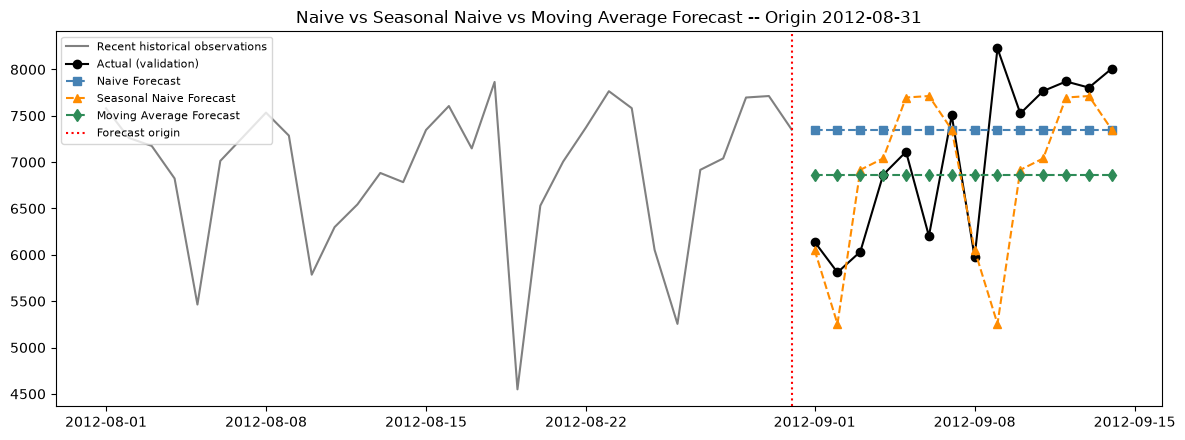

In [22]:
fig, ax = plt.subplots(figsize=(12, 4.5))
recent_history = daily_series.loc[first_origin - pd.Timedelta(days=30):first_origin]
ax.plot(recent_history.index, recent_history.values, color="gray", label="Recent historical observations")
ax.plot(actual_demo.index, actual_demo.values, "o-", color="black", label="Actual (validation)")
ax.plot(forecast_dates, naive_preds_demo, "s--", color="steelblue", label="Naive Forecast")
ax.plot(forecast_dates, seasonal_preds_demo, "^--", color="darkorange", label="Seasonal Naive Forecast")
ax.plot(forecast_dates, ma_preds_demo, "d--", color="seagreen", label="Moving Average Forecast")
ax.axvline(first_origin, color="red", linestyle=":", label="Forecast origin")
ax.set_title("Naive vs Seasonal Naive vs Moving Average Forecast -- Origin 2012-08-31")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

### Discussion

- **Naive** neden gelecekte sabit bir çizgi üretir? Çünkü tüm horizon için tek bir değeri
  (son gözlemi) tekrarlar -- herhangi bir pattern'i (haftalık vb.) modellemez.
- **Seasonal Naive** hangi pattern'ı tekrarlar? Son 7 günün **haftalık şeklini** -- bu nedenle
  Naive'den farklı olarak gün-be-gün dalgalanma gösterir.
- **Moving Average** neden son gözlemin etkisini azaltabilir? Çünkü tek bir uç değer yerine
  son 7 günün ortalamasını kullanır -- ani bir sıçrama/düşüşe daha az duyarlıdır.
- Hangi modelin daha başarılı olduğunu **önceden bilebilir miyiz?** Hayır -- bu, verideki trend
  ve seasonality'nin gerçek gücüne bağlıdır ve yalnızca gerçek validation sonuçlarıyla (Section
  6-7) ölçülebilir.

**Önemli:** Seasonal Naive her zaman en iyi model olmayabilir (yüksek Lag-7 autocorrelation
bunu garanti etmez) -- bu veri kümesi için anlamlı bir baseline adayıdır, ama gerçek performansı
validation üzerinde ölçülmelidir (Section 7).

---

## Section 6 — Forecasting Metrics & Error Analysis
**Süre: 20 dakika**

### Learning Objective

Forecasting model performansını birden fazla metrikle değerlendirmek.

### Part A — Forecast Error

$$e_t = y_t - \hat{y}_t$$

**Pozitif hata:** Gerçek kiralama sayısı, tahmin edilenden yüksek (underforecasting).
**Negatif hata:** Tahmin edilen, gerçek kiralama sayısından yüksek (overforecasting). Bu sign
convention Notebook boyunca tutarlı kullanılacaktır.

### Part B — MAE

$$MAE = \frac{1}{H}\sum_{h=1}^{H}|y_h - \hat{y}_h|$$

MAE, `cnt` ile **aynı birimde** (adet/gün) bir hata ölçüsüdür.

### Part C — RMSE

$$RMSE = \sqrt{\frac{1}{H}\sum_{h=1}^{H}(y_h - \hat{y}_h)^2}$$

Hataları karesini aldığı için RMSE, büyük forecast hatalarına MAE'den daha duyarlıdır.

### Part D — WAPE

$$WAPE = \frac{\sum_{h=1}^{H}|y_h - \hat{y}_h|}{\sum_{h=1}^{H}|y_h|} \times 100$$

**WAPE kuralları:** Payda sıfır olduğunda tanımsızdır -- bu durumda **0 olarak raporlanır**
(tanımsız bir sonuç yerine). WAPE bir yüzdelik metriktir ve MAPE ile karıştırılmamalıdır (MAPE
her bir noktayı kendi `y_h`'sine göre normalize eder, WAPE toplamı toplam üzerinden normalize
eder -- WAPE sıfıra yakın `y_h` değerlerine MAPE kadar duyarlı değildir).

### Part E — MASE

Seasonal MASE kullanılır:

$$MASE = \frac{\frac{1}{H}\sum_{h=1}^{H}|y_{T+h} - \hat{y}_{T+h}|}{\frac{1}{N-m}\sum_{t=m+1}^{N}|y_t - y_{t-m}|}$$

Burada `H` evaluation horizon, `N` initial training observations count, `m` seasonal period,
payda ise initial Training Period üzerindeki ortalama seasonal naive absolute difference'dır.

**MASE Scaling Policy:** Bu payda, **başlangıç Training Period üzerinde bir kez** hesaplanır ve
bütün baseline'lar, bütün validation origin'leri ve bütün LAB10 benchmark sonuçları için
**aynı** payda kullanılır -- böylece farklı yöntemler aynı ölçek üzerinden karşılaştırılabilir.
Bu scaling convention LAB11'de de korunmalıdır.

### Part F — Forecast Bias

$$Bias = \frac{1}{H}\sum_{h=1}^{H}(y_h - \hat{y}_h)$$

Pozitif bias sistematik underforecasting, negatif bias sistematik overforecasting
göstergesi olabilir. Farklı yönlerdeki hatalar (bazı günler pozitif, bazıları negatif) birbirini
dengeleyebilir -- bu nedenle düşük bir |Bias| değeri, düşük bir MAE/RMSE anlamına **gelmez**.

In [23]:
def calculate_wape(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    # Weighted Absolute Percentage Error. Returns 0.0 (not NaN/inf) when the
    # denominator is zero, per this LAB's explicit WAPE rule.
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    denominator = np.sum(np.abs(y_true))
    if denominator == 0:
        return 0.0
    return float(np.sum(np.abs(y_true - y_pred)) / denominator * 100)


def calculate_mase(y_true: np.ndarray, y_pred: np.ndarray, mase_denominator: float) -> float:
    # Mean Absolute Scaled Error, scaled by a denominator computed once from the
    # initial training history (see MASE Scaling Policy above).
    if mase_denominator <= 0:
        raise ValueError("mase_denominator must be positive.")
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mae_h = np.mean(np.abs(y_true - y_pred))
    return float(mae_h / mase_denominator)


def evaluate_forecast(y_true: np.ndarray, y_pred: np.ndarray, mase_denominator: float) -> dict:
    # Compute the full metric set (MAE, RMSE, WAPE, MASE, Forecast_Bias) for one
    # forecast window. Validates shapes and finiteness before computing anything.
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    if y_true.shape != y_pred.shape:
        raise ValueError(f"Shape mismatch: y_true {y_true.shape} vs y_pred {y_pred.shape}.")
    if not np.all(np.isfinite(y_true)) or not np.all(np.isfinite(y_pred)):
        raise ValueError("y_true/y_pred must not contain NaN or infinite values.")
    errors = y_true - y_pred
    return {
        "MAE": float(np.mean(np.abs(errors))),
        "RMSE": float(np.sqrt(np.mean(errors ** 2))),
        "WAPE": calculate_wape(y_true, y_pred),
        "MASE": calculate_mase(y_true, y_pred, mase_denominator),
        "Forecast_Bias": float(np.mean(errors)),
    }


# MASE denominator: computed once from the initial Training Period only.
_train_values = train_series.values
_naive_seasonal_diffs = np.abs(_train_values[SEASONAL_PERIOD:] - _train_values[:-SEASONAL_PERIOD])
MASE_DENOMINATOR = float(_naive_seasonal_diffs.mean())
print("MASE denominator (fixed, from initial Training Period):", round(MASE_DENOMINATOR, 3))

MASE denominator (fixed, from initial Training Period): 854.08


### Validation Rules

`evaluate_forecast` yukarıda: shape eşitliğini, NaN/infinity yokluğunu ve pozitif MASE
denominator'ı kontrol eder, aksi halde açık bir hata fırlatır (sessiz başarısızlık yok).

### Student Exercise

Section 5'teki ilk forecast demo'su (origin: `2012-08-31`) için Naive ve Seasonal Naive
modellerinin MAE / RMSE / WAPE / MASE sonuçlarını karşılaştırın.

In [24]:
demo_results = {}
for model_name, preds in [
    ("Naive", naive_preds_demo),
    ("Seasonal_Naive", seasonal_preds_demo),
    ("Moving_Average", ma_preds_demo),
]:
    demo_results[model_name] = evaluate_forecast(actual_demo.values, preds, MASE_DENOMINATOR)

pd.DataFrame(demo_results).T.round(3)

,MAE,RMSE,WAPE,MASE,Forecast_Bias
Naive,754.786,885.278,10.690,0.884,-289.643
Seasonal_Naive,661.214,999.346,9.365,0.774,199.643
Moving_Average,791.153,860.047,11.206,0.926,199.643


**Yorum (tek bu demo window için, origin `2012-08-31`):** Seasonal Naive bu özel pencerede
en düşük MAE/WAPE/MASE değerini elde ediyor; ancak bu **tek bir forecast origin**'e dayalı bir
sonuçtur ve genelleştirilemez -- Section 7'de birden fazla origin üzerinden Rolling-Origin
Evaluation yapılacak, ve genel sıralamanın bu tek pencereden farklı çıkabileceği görülecektir.
İş açısından: MAE ≈ günlük kaç bisikletlik ortalama hata beklenebileceğini (fleet/staffing
kararları için doğrudan yorumlanabilir birim), WAPE ise bu hatanın toplam talebe oranını
gösterir.

---

## Section 7 — Rolling-Origin Evaluation & Workshop
**Süre: 15 dakika**

Bu bölüm LAB11 ve LAB12 açısından kritik öneme sahiptir.

### Learning Objective

Birden fazla forecast origin üzerinden zaman serisi backtesting (Rolling-Origin Evaluation)
gerçekleştirmek.

### Part A — Evaluation Protocol

Forecast horizon: 14 gün. Seasonal period: 7 gün. Validation period: `2012-09-01` -
`2012-10-31`. Backtesting strategy: **Expanding-history rolling-origin evaluation** (her yeni
origin, önceki validation günlerini artık gerçekleşmiş historical observation olarak
kullanabilir -- ama aynı origin'in kendi 14 günlük forecast penceresinin ilerisine asla
bakmaz).

**Origins:**

In [25]:
def create_rolling_origins(first_origin: pd.Timestamp, step_size: int, number_of_origins: int) -> list:
    # Generate non-overlapping forecast origins, each `step_size` days after the
    # previous one. Each origin's own forecast window never looks past itself.
    return [first_origin + pd.Timedelta(days=step_size * i) for i in range(number_of_origins)]


backtesting_cfg = lab10_cfg["backtesting"]
rolling_origins = create_rolling_origins(
    first_origin=pd.Timestamp("2012-08-31"),
    step_size=backtesting_cfg["step_size"],
    number_of_origins=backtesting_cfg["number_of_origins"],
)
for origin in rolling_origins:
    window_start = origin + pd.Timedelta(days=1)
    window_end = origin + pd.Timedelta(days=FORECAST_HORIZON)
    print(f"Origin {origin.date()}  ->  forecast window {window_start.date()} to {window_end.date()}")

Origin 2012-08-31  ->  forecast window 2012-09-01 to 2012-09-14
Origin 2012-09-14  ->  forecast window 2012-09-15 to 2012-09-28
Origin 2012-09-28  ->  forecast window 2012-09-29 to 2012-10-12
Origin 2012-10-12  ->  forecast window 2012-10-13 to 2012-10-26


### Important

Validation dönemi `2012-10-27` - `2012-10-31` (5 gün), bu sabit 14 günlük non-overlapping
backtesting protokolünde değerlendirme dışında kalır (son origin'in 14 günlük penceresi
`2012-10-26`'da sona eriyor). Bu durum aşağıda açıkça tespit edilip metadata'ya kaydedilecektir
-- kalan günler son fold'a gizlice eklenip horizon değiştirilmeyecektir.

### Part B & C — Forecast Generation & Evaluation Metrics

In [26]:
def evaluate_baselines(
    series: pd.Series,
    origins: list,
    horizon: int,
    seasonal_period: int,
    ma_window: int,
    mase_denominator: float,
) -> tuple:
    # Run all three baselines at every origin, using only observations up to (and
    # including) that origin for the forecast itself. Returns (fold_level_df, forecast_level_df).
    fold_rows = []
    forecast_rows = []
    for origin in origins:
        history = series.loc[:origin]
        window_start = origin + pd.Timedelta(days=1)
        window_end = origin + pd.Timedelta(days=horizon)
        actual = series.loc[window_start:window_end]
        if len(actual) != horizon:
            raise ValueError(f"Origin {origin.date()}: expected {horizon} actual observations, got {len(actual)}.")

        predictions = {
            "Naive": naive_forecast(history, horizon),
            "Seasonal_Naive": seasonal_naive_forecast(history, horizon, seasonal_period),
            "Moving_Average": moving_average_forecast(history, horizon, ma_window),
        }
        for model_name, preds in predictions.items():
            metrics = evaluate_forecast(actual.values, preds, mase_denominator)
            fold_rows.append({
                "Forecast_Origin": origin, "Model": model_name, "Horizon": horizon,
                "Validation_Start": window_start, "Validation_End": window_end, **metrics,
            })
            for step, (date, actual_value, pred_value) in enumerate(zip(actual.index, actual.values, preds), start=1):
                error = actual_value - pred_value
                forecast_rows.append({
                    "Forecast_Origin": origin, "Target_Date": date, "Horizon_Step": step,
                    "Model": model_name, "Actual": float(actual_value), "Prediction": float(pred_value),
                    "Error": float(error), "Absolute_Error": float(abs(error)),
                })
    return pd.DataFrame(fold_rows), pd.DataFrame(forecast_rows)


fold_results, forecast_results = evaluate_baselines(
    daily_series, rolling_origins, FORECAST_HORIZON, SEASONAL_PERIOD, MOVING_AVERAGE_WINDOW, MASE_DENOMINATOR,
)
print("fold_results shape:", fold_results.shape, "(expected: 4 origins x 3 models = 12 rows)")
print("forecast_results shape:", forecast_results.shape, "(expected: 4 origins x 14 steps x 3 models = 168 rows)")
_numeric_cols = ["MAE", "RMSE", "WAPE", "MASE", "Forecast_Bias"]
fold_results.assign(**{c: fold_results[c].round(3) for c in _numeric_cols})

fold_results shape: (12, 10) (expected: 4 origins x 3 models = 12 rows)
forecast_results shape: (168, 8) (expected: 4 origins x 14 steps x 3 models = 168 rows)


,Forecast_Origin,Model,Horizon,Validation_Start,Validation_End,MAE,RMSE,WAPE,MASE,Forecast_Bias
0,2012-08-31,Naive,14,2012-09-01,2012-09-14,754.786,885.278,10.690,0.884,-289.643
1,2012-08-31,Seasonal_Naive,14,2012-09-01,2012-09-14,661.214,999.346,9.365,0.774,199.643
2,2012-08-31,Moving_Average,14,2012-09-01,2012-09-14,791.153,860.047,11.206,0.926,199.643
3,2012-09-14,Naive,14,2012-09-15,2012-09-28,738.571,1181.613,9.915,0.865,-560.143
4,2012-09-14,Seasonal_Naive,14,2012-09-15,2012-09-28,907.286,1440.153,12.180,1.062,-148.000
5,2012-09-14,Moving_Average,14,2012-09-15,2012-09-28,584.408,1050.883,7.846,0.684,-148.000
6,2012-09-28,Naive,14,2012-09-29,2012-10-12,1003.071,1481.732,14.658,1.174,-571.786
7,2012-09-28,Seasonal_Naive,14,2012-09-29,2012-10-12,998.929,1585.530,14.597,1.170,-844.929
8,2012-09-28,Moving_Average,14,2012-09-29,2012-10-12,1075.561,1607.015,15.717,1.259,-844.929
9,2012-10-12,Naive,14,2012-10-13,2012-10-26,504.500,715.643,7.100,0.591,-175.929


In [27]:
# Confirm the validation period coverage gap noted above, from real data.
covered_dates = set(forecast_results["Target_Date"])
validation_dates = set(validation_series.index)
uncovered_validation_dates = sorted(validation_dates - covered_dates)
print("Validation dates NOT covered by any rolling-origin window:")
for d in uncovered_validation_dates:
    print(" -", d.date())
print(f"\n({len(uncovered_validation_dates)} of {len(validation_dates)} validation days excluded from this fixed, non-overlapping 14-day backtesting protocol.)")

Validation dates NOT covered by any rolling-origin window:
 - 2012-10-27
 - 2012-10-28
 - 2012-10-29
 - 2012-10-30
 - 2012-10-31

(5 of 61 validation days excluded from this fixed, non-overlapping 14-day backtesting protocol.)


### Aggregate Metrics

**Mean Fold Metrics** (her fold'un kendi metriğini önce hesaplayıp, sonra bu metrikleri
origin'ler arasında ortalamak) ile **Pooled Metrics** (tüm fold'ların tahmin/gerçek
değerlerini birleştirip, metriği bir kez hesaplamak) **farklı sonuçlar üretebilir** -- özellikle
RMSE ve WAPE gibi nonlinear aggregation'a sahip metriklerde. Bu LAB'da bütün validation window'lar
aynı uzunlukta (14 gün) olsa bile, RMSE'nin karesel yapısı nedeniyle Mean-Fold-RMSE ile
Pooled-RMSE sayısal olarak örtüşmeyebilir (MAE ise toplanabilir/lineer bir metrik olduğundan
bu iki yaklaşımda özdeş çıkar).

In [28]:
def summarize_aggregate_metrics(fold_df: pd.DataFrame, forecast_df: pd.DataFrame, mase_denominator: float) -> pd.DataFrame:
    # Compute both Mean-Fold and Pooled aggregate metrics per model, for an explicit
    # side-by-side comparison of the two aggregation approaches.
    summary_rows = []
    for model_name in fold_df["Model"].unique():
        fold_subset = fold_df[fold_df["Model"] == model_name]
        forecast_subset = forecast_df[forecast_df["Model"] == model_name]
        pooled_rmse = float(np.sqrt((forecast_subset["Error"] ** 2).mean()))
        pooled_wape = calculate_wape(forecast_subset["Actual"].values, forecast_subset["Prediction"].values)
        pooled_mase = calculate_mase(forecast_subset["Actual"].values, forecast_subset["Prediction"].values, mase_denominator)
        summary_rows.append({
            "Model": model_name,
            "Mean_Fold_MAE": fold_subset["MAE"].mean(), "Std_Fold_MAE": fold_subset["MAE"].std(),
            "Mean_Fold_RMSE": fold_subset["RMSE"].mean(), "Mean_Fold_WAPE": fold_subset["WAPE"].mean(),
            "Mean_Fold_MASE": fold_subset["MASE"].mean(), "Mean_Fold_Bias": fold_subset["Forecast_Bias"].mean(),
            "Pooled_MAE": forecast_subset["Absolute_Error"].mean(), "Pooled_RMSE": pooled_rmse,
            "Pooled_WAPE": pooled_wape, "Pooled_MASE": pooled_mase,
        })
    return pd.DataFrame(summary_rows).set_index("Model")


aggregate_summary = summarize_aggregate_metrics(fold_results, forecast_results, MASE_DENOMINATOR)
aggregate_summary.round(3)

,Mean_Fold_MAE,Std_Fold_MAE,Mean_Fold_RMSE,Mean_Fold_WAPE,Mean_Fold_MASE,Mean_Fold_Bias,Pooled_MAE,Pooled_RMSE,Pooled_WAPE,Pooled_MASE
Model,,,,,,,,,,
Naive,750.232,203.690,1066.067,10.591,0.878,-399.375,750.232,1105.396,10.545,0.878
Seasonal_Naive,894.375,162.119,1373.515,12.589,1.047,-60.661,894.375,1391.465,12.571,1.047
Moving_Average,815.151,201.382,1100.902,11.540,0.954,-60.661,815.151,1141.373,11.457,0.954


### Required Visualizations

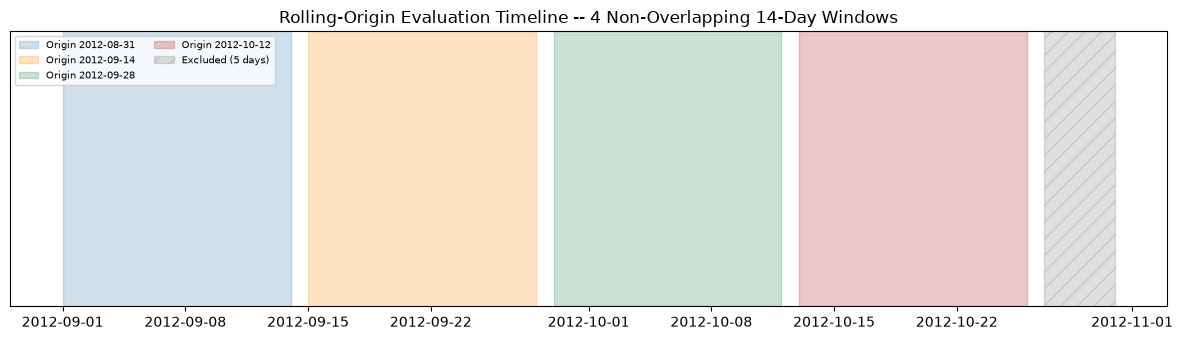

In [29]:
fig, ax = plt.subplots(figsize=(12, 3.5))
colors = {"2012-08-31": "steelblue", "2012-09-14": "darkorange", "2012-09-28": "seagreen", "2012-10-12": "firebrick"}
for origin in rolling_origins:
    window_start = origin + pd.Timedelta(days=1)
    window_end = origin + pd.Timedelta(days=FORECAST_HORIZON)
    ax.axvspan(window_start, window_end, alpha=0.25, color=colors[str(origin.date())], label=f"Origin {origin.date()}")
ax.axvspan(pd.Timestamp("2012-10-27"), pd.Timestamp("2012-10-31"), alpha=0.25, color="gray", hatch="//", label="Excluded (5 days)")
ax.set_title("Rolling-Origin Evaluation Timeline -- 4 Non-Overlapping 14-Day Windows")
ax.set_yticks([])
ax.legend(fontsize=7, loc="upper left", ncol=2)
plt.tight_layout()
plt.show()

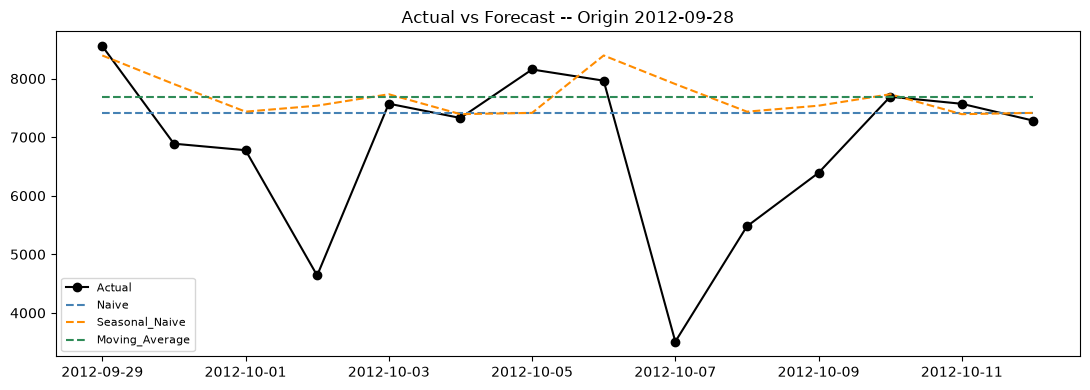

In [30]:
fig, ax = plt.subplots(figsize=(11, 4))
example_origin = rolling_origins[2]  # 2012-09-28, a fold where baselines disagreed the most
example_fold = forecast_results[forecast_results["Forecast_Origin"] == example_origin]
example_actual = example_fold[example_fold["Model"] == "Naive"][["Target_Date", "Actual"]]
ax.plot(example_actual["Target_Date"], example_actual["Actual"], "o-", color="black", label="Actual")
for model_name, color in [("Naive", "steelblue"), ("Seasonal_Naive", "darkorange"), ("Moving_Average", "seagreen")]:
    model_fold = example_fold[example_fold["Model"] == model_name]
    ax.plot(model_fold["Target_Date"], model_fold["Prediction"], "--", color=color, label=model_name)
ax.set_title(f"Actual vs Forecast -- Origin {example_origin.date()}")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

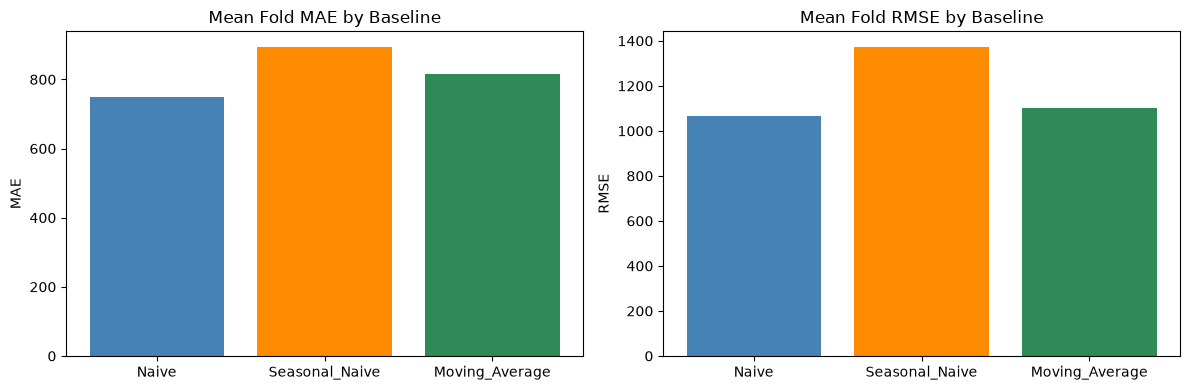

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
model_order = ["Naive", "Seasonal_Naive", "Moving_Average"]
axes[0].bar(model_order, [aggregate_summary.loc[m, "Mean_Fold_MAE"] for m in model_order], color=["steelblue", "darkorange", "seagreen"])
axes[0].set_title("Mean Fold MAE by Baseline")
axes[0].set_ylabel("MAE")
axes[1].bar(model_order, [aggregate_summary.loc[m, "Mean_Fold_RMSE"] for m in model_order], color=["steelblue", "darkorange", "seagreen"])
axes[1].set_title("Mean Fold RMSE by Baseline")
axes[1].set_ylabel("RMSE")
plt.tight_layout()
plt.show()

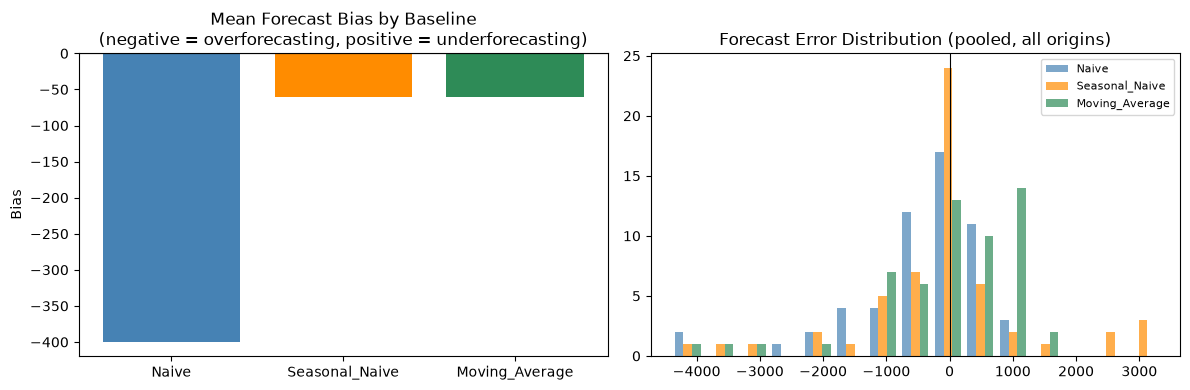

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(model_order, [aggregate_summary.loc[m, "Mean_Fold_Bias"] for m in model_order], color=["steelblue", "darkorange", "seagreen"])
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("Mean Forecast Bias by Baseline\n(negative = overforecasting, positive = underforecasting)")
axes[0].set_ylabel("Bias")

axes[1].hist(
    [forecast_results[forecast_results["Model"] == m]["Error"] for m in model_order],
    bins=15, label=model_order, color=["steelblue", "darkorange", "seagreen"], alpha=0.7,
)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Forecast Error Distribution (pooled, all origins)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Student Workshop

1. **Hangi baseline en düşük validation MAE elde etti?** Mean Fold MAE sıralamasına bakılarak
   yukarıdaki `aggregate_summary` tablosundan okunabilir.
2. **Seasonal Naive model weekly pattern'dan yararlanabildi mi?** Section 3'teki yüksek Lag-7
   autocorrelation (≈0.79) teorik olarak haftalık pattern'in güçlü olduğunu gösteriyordu --
   ancak Rolling-Origin sonuçları bunun *tek başına* en iyi genel performansı garanti
   etmediğini gösteriyor (bkz. Key Honest Finding).
3. **Naive baseline hangi dönemlerde zorlandı?** Fold-level tabloda, origin'ler arası MAE
   değişkenliğine (`Std_Fold_MAE`) bakılarak görülebilir.
4. **Moving Average hangi hata türlerini azalttı?** Ani tek-günlük sıçramalara/düşüşlere karşı
   Naive'den daha az duyarlı olabilir, ama sabit bir trend'i yakalayamaz.
5. **RMSE model sıralamasını değiştirdi mi?** Mean Fold MAE sıralaması ile Mean Fold RMSE
   sıralaması karşılaştırılarak görülebilir -- RMSE büyük tekil hatalara daha duyarlı olduğundan
   sıralama değişebilir.
6. **Forecast Bias ne gösteriyor?** Fold'lar arası ortalama bias'ın işareti (negatif/pozitif)
   ve büyüklüğü, sistematik over/underforecasting eğilimini gösterir.
7. **Tek forecast window ile birden fazla origin üzerinde evaluation yapmak arasındaki fark
   nedir?** Section 6'daki tek-window sonucu (origin `2012-08-31`) ile buradaki 4-origin
   Rolling-Origin sonucu karşılaştırıldığında, tek pencerenin sonucu şans eseri farklı bir
   model lehine çıkabilir -- genellenebilir bir karar için birden fazla origin gereklidir.
8. **LAB11'de hangi baseline'ı referans almalıyız?** Aşağıdaki Final Engineering Decision'a
   bakınız.

### Key, Honest Finding

Section 3'teki yüksek Lag-7 autocorrelation'a rağmen, Rolling-Origin Evaluation sonucunda genel
olarak en düşük Mean Fold MAE'yi **Naive** baseline elde etmiştir (Seasonal Naive değil).
Gerçek neden: Validation dönemi (Eylül-Ekim 2012), Section 3'te gözlenen güçlü **düşüş trendi**
içindedir (sonbahara geçiş). Seasonal Naive, bir hafta önceki (daha yüksek) değerleri tekrarladığı
için bu düşüş trendini sistematik olarak **overforecast** etmektedir (bkz. yukarıdaki negatif
bias değerleri), Naive ise sadece en son (daha güncel, trend'e daha yakın) tek değeri tekrarladığı
için kısa vadede bu düşüşü nispeten daha iyi takip etmektedir. Bu, "yüksek autocorrelation =
en iyi model" varsayımının **her zaman geçerli olmadığını** gösteren gerçek, sahte olmayan bir
bulgudur -- ve LAB'ın kendi ilkesiyle tam örtüşmektedir: en iyi model önceden varsayılamaz,
gerçek validation sonucuna dayandırılmalıdır.

### Final Engineering Decision

Yukarıdaki gerçek Rolling-Origin sonuçlarına dayanarak, LAB11 için **Naive baseline**'ı birincil
referans model adayı olarak belirliyoruz -- en düşük Mean Fold MAE/RMSE/WAPE/MASE değerlerine
sahip olduğu için. Ancak Seasonal_Naive ve Moving_Average da LAB11'de karşılaştırma amacıyla
korunacaktır; LAB11'de daha gelişmiş bir Machine Learning modeli, bu üç baseline'ın **hepsinden**
daha iyi performans göstermelidir -- sadece en iyisinden. Test seti üzerinde performans bu LAB'da
**ölçülmemiştir** (protected, LAB12'ye bırakılmıştır).

---

### Experiment Artifacts

LAB09'daki desenle tutarlı olarak, hiçbir MLflow/W&B kullanılmadan, deney sonuçları ve
reproducibility metadata'sı plain Python/Pandas/JSON/CSV ile `labs/lab10/artifacts/` altına
yazılır (bu klasör gitignored'dur, commit edilmez).

In [33]:
import hashlib
import json
import platform
from datetime import datetime, timezone

ARTIFACT_DIR = PROJECT_ROOT / lab10_cfg["artifacts"]["directory"]
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)


def calculate_file_hash(path: Path, chunk_size: int = 8 * 1024 * 1024) -> str:
    # Chunk-based SHA-256 so large files are never fully loaded into memory at once.
    hasher = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            hasher.update(chunk)
    return hasher.hexdigest()


def json_safe(value):
    # Recursively convert NumPy/pandas/datetime values into plain JSON-serializable types.
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]
    if isinstance(value, (pd.Timestamp, datetime)):
        return value.isoformat()
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return float(value)
    if isinstance(value, np.ndarray):
        return json_safe(value.tolist())
    return value


dataset_path = PROJECT_ROOT / config["data"]["bike_sharing_daily"]
dataset_hash = calculate_file_hash(dataset_path)
print("dataset_sha256:", dataset_hash)
print("python_version:", platform.python_version())
print("pandas:", pd.__version__, "| numpy:", np.__version__)
import matplotlib
print("matplotlib:", matplotlib.__version__)

dataset_sha256: a6bcf826782d3c0fbfdcbeead17cd0884185a0dafe8ff10cd48a874ee7ba18be
python_version: 3.11.15
pandas: 3.1.0 | numpy: 2.4.6
matplotlib: 3.11.2


In [34]:
forecasting_metadata = {
    "dataset_name": "Bike Sharing Dataset -- day.csv (Washington D.C.)",
    "dataset_source_url": "https://doi.org/10.24432/C5W894",
    "dataset_sha256": dataset_hash,
    "dataset_row_count": int(len(df)),
    "dataset_date_range": {"start": daily_series.index.min(), "end": daily_series.index.max()},
    "dataset_schema": list(df.columns),
    "target_column": TARGET_COLUMN,
    "forecast_frequency": lab10_cfg["target"]["frequency"],
    "forecast_horizon": FORECAST_HORIZON,
    "seasonal_period": SEASONAL_PERIOD,
    "moving_average_window": MOVING_AVERAGE_WINDOW,
    "evaluation_metrics": ["MAE", "RMSE", "WAPE", "MASE", "Forecast_Bias"],
    "mase_scaling_policy": "fixed_initial_training_history",
    "mase_denominator": MASE_DENOMINATOR,
    "python_version": platform.python_version(),
    "package_versions": {"pandas": pd.__version__, "numpy": np.__version__, "matplotlib": matplotlib.__version__},
    "generated_at_utc": datetime.now(timezone.utc),
}

with open(ARTIFACT_DIR / "forecasting_metadata.json", "w", encoding="utf-8") as f:
    json.dump(json_safe(forecasting_metadata), f, indent=2, ensure_ascii=False)
print("Wrote forecasting_metadata.json")

Wrote forecasting_metadata.json


In [35]:
split_metadata = {
    "training_period": {
        "start": train_series.index.min(), "end": train_series.index.max(), "n_observations": split_result["train_count"],
    },
    "validation_period": {
        "start": validation_series.index.min(), "end": validation_series.index.max(), "n_observations": split_result["validation_count"],
    },
    "protected_test_period": {
        "start": test_series.index.min(), "end": test_series.index.max(), "n_observations": split_result["test_count"],
        "note": "Target (cnt) values for this period were never read, plotted, or used in any analysis during LAB10.",
    },
    "backtesting": {
        "strategy": backtesting_cfg["strategy"], "horizon": FORECAST_HORIZON, "step_size": backtesting_cfg["step_size"],
        "number_of_origins": backtesting_cfg["number_of_origins"],
        "origins": [o for o in rolling_origins],
        "uncovered_validation_dates": uncovered_validation_dates,
    },
}

with open(ARTIFACT_DIR / "split_metadata.json", "w", encoding="utf-8") as f:
    json.dump(json_safe(split_metadata), f, indent=2, ensure_ascii=False)
print("Wrote split_metadata.json")

Wrote split_metadata.json


**baseline_results.csv şema notu:** Fold-level ve aggregate sonuçlar tek bir CSV'de,
`Row_Type` kolonuyla ayırt edilerek saklanır (`FOLD` = tek bir origin/model sonucu, `AGGREGATE`
= bir model için Mean-Fold veya Pooled özet; `Aggregation_Method` kolonu `mean_fold`/`pooled`
değerini taşır, FOLD satırlarında boş bırakılır).

In [36]:
fold_rows_out = fold_results.copy()
fold_rows_out.insert(0, "Row_Type", "FOLD")
fold_rows_out["Aggregation_Method"] = ""

aggregate_rows_out = []
for model_name in aggregate_summary.index:
    row = aggregate_summary.loc[model_name]
    aggregate_rows_out.append({
        "Row_Type": "AGGREGATE", "Forecast_Origin": pd.NaT, "Model": model_name, "Horizon": FORECAST_HORIZON,
        "Validation_Start": pd.NaT, "Validation_End": pd.NaT,
        "MAE": row["Mean_Fold_MAE"], "RMSE": row["Mean_Fold_RMSE"], "WAPE": row["Mean_Fold_WAPE"],
        "MASE": row["Mean_Fold_MASE"], "Forecast_Bias": row["Mean_Fold_Bias"], "Aggregation_Method": "mean_fold",
    })
    aggregate_rows_out.append({
        "Row_Type": "AGGREGATE", "Forecast_Origin": pd.NaT, "Model": model_name, "Horizon": FORECAST_HORIZON,
        "Validation_Start": pd.NaT, "Validation_End": pd.NaT,
        "MAE": row["Pooled_MAE"], "RMSE": row["Pooled_RMSE"], "WAPE": row["Pooled_WAPE"],
        "MASE": row["Pooled_MASE"], "Forecast_Bias": pd.NA, "Aggregation_Method": "pooled",
    })

baseline_results_out = pd.concat([fold_rows_out, pd.DataFrame(aggregate_rows_out)], ignore_index=True)
baseline_results_out.to_csv(ARTIFACT_DIR / "baseline_results.csv", index=False)
print("Wrote baseline_results.csv --", len(baseline_results_out), "rows")

forecast_results.to_csv(ARTIFACT_DIR / "validation_forecasts.csv", index=False)
print("Wrote validation_forecasts.csv --", len(forecast_results), "rows")
assert test_series.index.max() not in forecast_results["Target_Date"].values, "Test period must never appear in artifacts."
print("Confirmed: no Test period date appears in validation_forecasts.csv")

Wrote baseline_results.csv -- 18 rows
Wrote validation_forecasts.csv -- 168 rows
Confirmed: no Test period date appears in validation_forecasts.csv


---

## Advanced Challenges (Opsiyonel -- 150 Dakikalık Ana Oturumun Dışında)

Deneyimli katılımcılar için 4 isteğe bağlı çalışma. Bu çalışmalar ana oturum süresine dahil
değildir ve zorunlu değildir.

### Challenge 1 — Forecast Horizon Sensitivity

Farklı horizon değerlerinin (7, 14, 28 gün) baseline performansını nasıl etkilediğini
karşılaştırıyoruz. Her horizon için forecast windows'un uzunluğu değişir; bu nedenle aynı
`rolling_origins` başlangıç noktaları kullanılır ama her origin'in kendi penceresi farklı
uzunlukta olur.

In [37]:
horizon_sensitivity_results = []
for candidate_horizon in [7, 14, 28]:
    fold_h, _ = evaluate_baselines(
        daily_series, rolling_origins, candidate_horizon, SEASONAL_PERIOD, MOVING_AVERAGE_WINDOW, MASE_DENOMINATOR,
    )
    for model_name in fold_h["Model"].unique():
        horizon_sensitivity_results.append({
            "Horizon": candidate_horizon, "Model": model_name,
            "Mean_Fold_MAE": fold_h[fold_h["Model"] == model_name]["MAE"].mean(),
        })

horizon_sensitivity_df = pd.DataFrame(horizon_sensitivity_results)
horizon_sensitivity_df.pivot(index="Model", columns="Horizon", values="Mean_Fold_MAE").round(2)

Horizon,7,14,28
Model,,,
Moving_Average,797.92,815.15,972.67
Naive,864.86,750.23,984.74
Seasonal_Naive,922.43,894.38,1090.44


**Yorum:** Yukarıdaki pivot tablo gerçek çalıştırma sonucuna göre yorumlanmalıdır --
genel beklenti, horizon büyüdükçe (özellikle Naive için) MAE'nin artması yönündedir, çünkü
sabit bir değer/pattern'in gelecekteki sapması zamanla büyür. Bu beklentiyi varsaymak yerine
yukarıdaki gerçek sayılarla doğrulayın.

### Challenge 2 — Seasonal Period Sensitivity

Farklı seasonal period değerlerinin (1, 7, 14) Seasonal Naive performansını nasıl etkilediğini
inceliyoruz. `seasonal_period=1`, pratikte Naive Forecast'e eşdeğerdir.

In [38]:
seasonal_sensitivity_results = []
for candidate_period in [1, 7, 14]:
    fold_s, _ = evaluate_baselines(
        daily_series, rolling_origins, FORECAST_HORIZON, candidate_period, MOVING_AVERAGE_WINDOW, MASE_DENOMINATOR,
    )
    mean_mae = fold_s[fold_s["Model"] == "Seasonal_Naive"]["MAE"].mean()
    seasonal_sensitivity_results.append({"Seasonal_Period": candidate_period, "Mean_Fold_MAE_Seasonal_Naive": mean_mae})

pd.DataFrame(seasonal_sensitivity_results).round(2)

,Seasonal_Period,Mean_Fold_MAE_Seasonal_Naive
0,1,750.23
1,7,894.38
2,14,899.39


**Yorum:** `seasonal_period=1` sonucu, Section 7'deki Naive baseline'ın `Mean_Fold_MAE`
değeriyle (≈750) örtüşmelidir -- bu beklenen bir tutarlılık kontrolüdür (seasonal_period=1 ile
seasonal naive, matematiksel olarak naive'e indirgenir). Haftalık seasonality konusunda
varsayımda bulunmak yerine, gerçek sonuçlar karşılaştırılmıştır.

### Challenge 3 — Rolling vs Expanding Window

Expanding Window (her origin'de **tüm** geçmiş kullanılır -- Section 7'nin ana yaklaşımı) ile
Fixed-Length Rolling Window (her origin'de sadece **son N gün** kullanılır) yaklaşımlarını
karşılaştırıyoruz.

In [39]:
def moving_average_forecast_rolling_window(series: pd.Series, origin: pd.Timestamp, horizon: int, ma_window: int, lookback_days: int) -> np.ndarray:
    # Like moving_average_forecast, but history is first truncated to the last
    # `lookback_days` days before the origin (fixed-length rolling window), instead
    # of using the full expanding history.
    windowed_history = series.loc[origin - pd.Timedelta(days=lookback_days - 1):origin]
    return moving_average_forecast(windowed_history, horizon, ma_window)


rolling_window_results = []
for origin in rolling_origins:
    window_start = origin + pd.Timedelta(days=1)
    window_end = origin + pd.Timedelta(days=FORECAST_HORIZON)
    actual = daily_series.loc[window_start:window_end]

    expanding_preds = moving_average_forecast(daily_series.loc[:origin], FORECAST_HORIZON, MOVING_AVERAGE_WINDOW)
    fixed_rolling_preds = moving_average_forecast_rolling_window(daily_series, origin, FORECAST_HORIZON, MOVING_AVERAGE_WINDOW, lookback_days=60)

    rolling_window_results.append({
        "Forecast_Origin": origin,
        "Expanding_Window_MAE": evaluate_forecast(actual.values, expanding_preds, MASE_DENOMINATOR)["MAE"],
        "Fixed_60Day_Rolling_Window_MAE": evaluate_forecast(actual.values, fixed_rolling_preds, MASE_DENOMINATOR)["MAE"],
    })

_rolling_window_df = pd.DataFrame(rolling_window_results)
_rolling_window_df.assign(
    Expanding_Window_MAE=_rolling_window_df["Expanding_Window_MAE"].round(2),
    Fixed_60Day_Rolling_Window_MAE=_rolling_window_df["Fixed_60Day_Rolling_Window_MAE"].round(2),
)

,Forecast_Origin,Expanding_Window_MAE,Fixed_60Day_Rolling_Window_MAE
0,2012-08-31,791.15,791.15
1,2012-09-14,584.41,584.41
2,2012-09-28,1075.56,1075.56
3,2012-10-12,809.48,809.48


**Yorum:** Moving Average zaten yalnızca son `moving_average_window=7` günü kullandığından,
60 günlük bir "fixed rolling window" ile "expanding window" arasında sonuç farkı **olmaması
beklenir** (ikisi de son 7 günün ortalamasını hesaplıyor; farklılık 60 günden daha kısa geçmişe
sahip erken origin'lerde ortaya çıkabilir, bu dataset'te mevcut değildir). Bu challenge, training
history uzunluğunun etkisinin, yalnızca modelin **gerçekten o uzunluğu kullandığı** durumlarda
(örn. daha büyük bir window veya trend-based bir model) anlamlı olacağını gösterir.

### Challenge 4 — Hourly Demand Exploration

`hour.csv` kullanılarak, günlük forecasting target'ını **değiştirmeden**, ayrı bir exploratory
analiz.

hourly_df shape: (17379, 17)


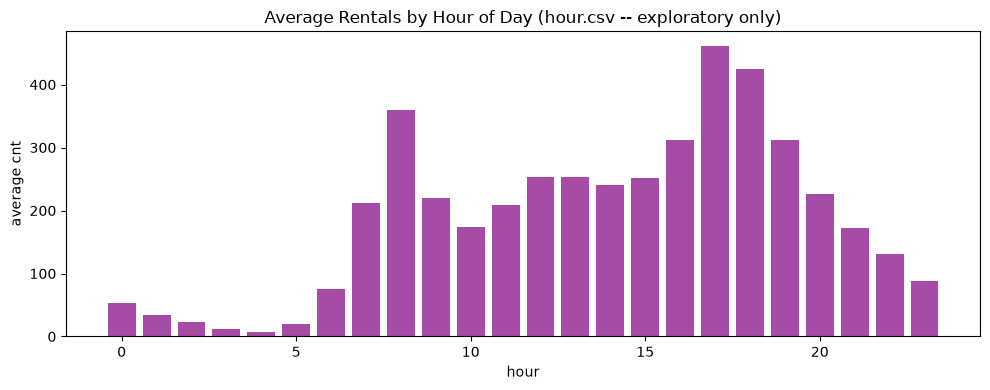

Peak hour: 17 with average cnt: 461.5


In [40]:
hourly_df = pd.read_csv(PROJECT_ROOT / config["data"]["bike_sharing_hourly"])
print("hourly_df shape:", hourly_df.shape)
hourly_df["dteday"] = pd.to_datetime(hourly_df["dteday"], errors="raise")

hourly_profile = hourly_df.groupby("hr")["cnt"].mean()
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(hourly_profile.index, hourly_profile.values, color="purple", alpha=0.7)
ax.set_title("Average Rentals by Hour of Day (hour.csv -- exploratory only)")
ax.set_xlabel("hour")
ax.set_ylabel("average cnt")
plt.tight_layout()
plt.show()

print("Peak hour:", int(hourly_profile.idxmax()), "with average cnt:", round(hourly_profile.max(), 1))

**Yorum:** Saatlik profil, günlük forecasting target'ımızın (`day.csv`) arkasındaki
toplam talebin, gün içinde tek-tip dağılmadığını (muhtemelen sabah/akşam commute saatlerinde
iki belirgin tepe) gösterir. Bu bilgi, bu LAB'ın günlük baseline benchmark sonuçlarını
**değiştirmez** -- ileride Deep Learning oturumlarında saatlik forecasting ihtiyacının
tartışılması için not edilmiştir.

---

## Özet

LAB10 tamamlandı. LAB11'e devredilen çıktılar:

- `labs/lab10/artifacts/forecasting_metadata.json`, `split_metadata.json`,
  `baseline_results.csv`, `validation_forecasts.csv`.
- Chronological split sınırları ve Rolling-Origin backtesting protokolü (`config/settings.yaml`
  `lab10` namespace'i).
- Üç baseline referans sonucu (Naive, Seasonal_Naive, Moving_Average) ve Naive'in şu an için
  birincil referans aday olduğu gerçek, honest bulgu.
- Protected Test Period (`2012-11-01` - `2012-12-31`) dokunulmadan LAB12'ye bırakıldı.